# **실습 개요**

여러분은 와인 감정 스타트업의 데이터 분석팀에 합류했습니다. <br>
이 회사는 와인의 화학 성분 분석 결과만으로 와인의 포도 품종(Cabernet Sauvignon / Merlot / Pinot Noir)을 <br>
자동으로 판별하는 모델을 만들어, 와이너리의 품질 관리 및 블라인드 테이스팅 검증에 활용하려고 합니다.

이번 실습에서는 **PyTorch `nn.Module` 기반 MLP**로 다중 분류 모델을 만듭니다.

## **데이터셋 설명**

와인 1,120병에 대한 화학 성분 분석 결과와 실제 포도 품종(정답)을 담은 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| alcohol | 알코올 함량 (%) |
| malic_acid | 사과산 함량 (g/L) |
| ash | 회분 함량 (g/L) |
| alcalinity_of_ash | 회분의 알칼리도 |
| magnesium | 마그네슘 함량 (mg/L) |
| total_phenols | 총 페놀 함량 |
| flavanoids | 플라보노이드 함량 |
| nonflavanoid_phenols | 비플라보노이드 페놀 함량 |
| proanthocyanins | 프로안토시아닌 함량 |
| color_intensity | 색상 강도 |
| hue | 색조 |
| od280_od315 | 단백질 함량 추정 흡광도 비율 (OD280/OD315) |
| proline | 프롤린(아미노산) 함량 |
| oak_aged | 오크통 숙성 여부 (Yes/No) |
| variety | **[target]** 포도 품종 (Cabernet Sauvignon / Merlot / Pinot Noir) |

## **이진 분류 vs 다중 분류**

| | 이진 분류 | 다중 분류 |
|---|---|---|
| 클래스 수 | 2개 | 3개 이상 |
| 출력층 | `Linear → Sigmoid` | `Linear` (Softmax 없음) |
| 손실 함수 | `BCELoss` | `CrossEntropyLoss` |
| 레이블 dtype | `float32` | `long` |

- CrossEntropyLoss는 내부적으로 Softmax를 포함하므로, 출력층에 Softmax를 따로 달면 이중 적용됩니다.

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv

## **1. 데이터 살펴보기**

**Q1. 필요한 라이브러리를 불러오고, 데이터를 읽어온 뒤 첫 5개의 행을 출력하세요.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged,variety
0,11.785199,1.169833,2.306773,24.208038,89.593547,2.290849,2.108096,0.243616,1.100715,3.786747,1.169956,2.721544,624.712679,No,Merlot
1,11.122725,4.103022,2.469871,19.018421,84.185270,2.201615,1.719580,0.295145,1.493834,3.831402,0.750554,1.774096,550.372477,NaN,Merlot
2,12.315376,1.079129,1.386586,25.770385,90.590014,1.280029,1.166926,0.420398,0.948833,3.828069,1.199902,2.289818,698.951732,Yes,Merlot
3,12.724482,0.879105,2.524974,17.036320,101.330910,3.054305,2.804751,0.322099,1.730976,5.741020,1.369589,3.248187,1331.241565,Yes,Cabernet Sauvignon
4,12.141689,1.730578,1.572926,17.286193,74.038796,2.123239,1.928006,0.310430,0.769692,2.921799,1.291609,2.859367,705.963614,Yes,Merlot


**Q2. 데이터의 크기와 컬럼별 정보를 확인합니다.**

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1120 entries, 0 to 1119
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   alcohol               1120 non-null   float64
 1   malic_acid            1076 non-null   float64
 2   ash                   1120 non-null   float64
 3   alcalinity_of_ash     1120 non-null   float64
 4   magnesium             1042 non-null   float64
 5   total_phenols         1120 non-null   float64
 6   flavanoids            1120 non-null   float64
 7   nonflavanoid_phenols  1120 non-null   float64
 8   proanthocyanins       1009 non-null   float64
 9   color_intensity       1120 non-null   float64
 10  hue                   950 non-null    float64
 11  od280_od315           1120 non-null   float64
 12  proline               1120 non-null   float64
 13  oak_aged              1065 non-null   str    
 14  variety               1120 non-null   str    
dtypes: float64(13), str(2)
memory us

**Q3. 수치형 컬럼들의 기술 통계량을 확인합니다.**

In [3]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
count,1120.000000,1076.000000,1120.000000,1120.000000,1042.000000,1120.000000,1120.000000,1120.000000,1009.000000,1120.000000,950.000000,1120.000000,1120.000000
mean,13.066331,2.392728,2.380684,19.429161,99.464946,2.261206,2.084462,0.359310,1.581669,5.260124,0.950130,2.239949,748.218360
std,0.743732,1.132270,0.268746,3.375890,13.667743,0.617484,0.591677,0.121769,0.564194,2.371496,0.232600,0.519387,325.478965
min,10.105443,0.010000,1.384772,9.610953,42.431242,0.631154,0.545046,0.010000,0.010000,0.010000,0.252342,1.000000,0.100000
25%,12.536712,1.661629,2.220090,17.169921,90.771697,1.750480,1.612300,0.274527,1.184345,3.397556,0.750700,1.802643,514.353543
50%,13.113841,2.294375,2.401088,19.488909,99.778662,2.280092,2.086256,0.347769,1.597912,5.010499,0.974036,2.328159,665.046603
75%,13.598016,2.986024,2.552149,21.743173,108.523987,2.779385,2.551304,0.431901,1.956663,6.638302,1.125602,2.643533,971.807935
max,15.156931,6.818836,3.232603,29.440284,150.495520,3.943020,3.736051,0.813198,4.015494,13.996794,1.747186,3.769422,2080.316615


## **2. 데이터 분석하기**

### **2-1. 데이터 탐색하기**

**Q1. 품종(variety)별 데이터의 개수를 찾아 주세요.**

In [4]:
q1 = df["variety"].value_counts()
q1

variety
Merlot                386
Cabernet Sauvignon    386
Pinot Noir            348
Name: count, dtype: int64

**Q2. 품종별로 alcohol, flavanoids, color_intensity의 평균을 소수점 2자리까지 구해 비교해 주세요.**

In [5]:
q2 = df.groupby("variety")[["alcohol", "flavanoids", "color_intensity"]].mean().round(2)
q2

,alcohol,flavanoids,color_intensity
variety,,,
Cabernet Sauvignon,13.70,2.60,5.45
Merlot,12.31,2.04,3.14
Pinot Noir,13.20,1.55,7.40


### **2-1. 데이터 시각화**

**Q1. alcohol 컬럼의 분포를 품종별로 histogram으로 시각화하세요.**

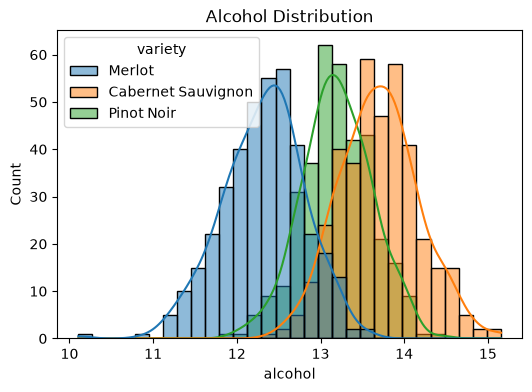

In [6]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="alcohol", bins=30, kde=True, hue="variety")
plt.title("Alcohol Distribution")
plt.show()

**Q2. 품종별 proline의 평균을 barplot으로 시각화하세요.**

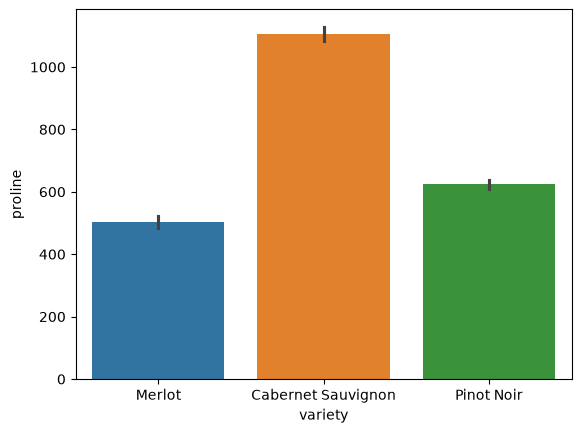

In [7]:
sns.barplot(data=df, x="variety", y="proline", hue="variety")
plt.show()

**Q3. 수치형 컬럼들의 상관관계 Heatmap을 시각화하세요.**

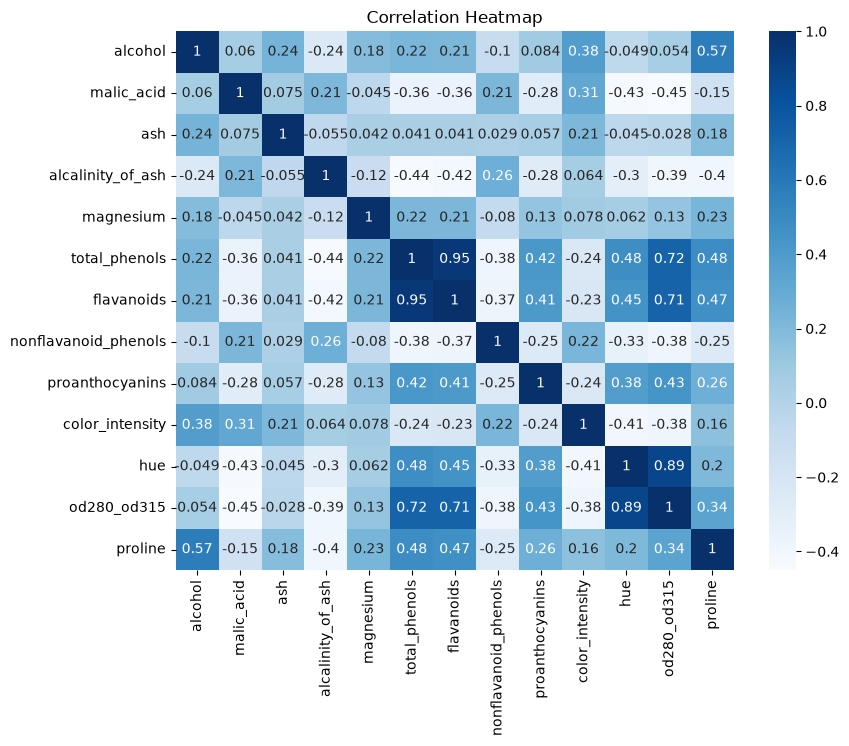

In [8]:
num_cols = df.select_dtypes(include="number").columns
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="Blues")
plt.title("Correlation Heatmap")
plt.show()

## **3. 데이터 전처리하기**

In [9]:
# 전처리 과정에서 데이터가 망가지면 여기서부터!
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged,variety
0,11.785199,1.169833,2.306773,24.208038,89.593547,2.290849,2.108096,0.243616,1.100715,3.786747,1.169956,2.721544,624.712679,No,Merlot
1,11.122725,4.103022,2.469871,19.018421,84.185270,2.201615,1.719580,0.295145,1.493834,3.831402,0.750554,1.774096,550.372477,NaN,Merlot
2,12.315376,1.079129,1.386586,25.770385,90.590014,1.280029,1.166926,0.420398,0.948833,3.828069,1.199902,2.289818,698.951732,Yes,Merlot
3,12.724482,0.879105,2.524974,17.036320,101.330910,3.054305,2.804751,0.322099,1.730976,5.741020,1.369589,3.248187,1331.241565,Yes,Cabernet Sauvignon
4,12.141689,1.730578,1.572926,17.286193,74.038796,2.123239,1.928006,0.310430,0.769692,2.921799,1.291609,2.859367,705.963614,Yes,Merlot


### **3-1. 중복 데이터 제거하기**

In [10]:
print("중복 행:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("제거 후 shape:", df.shape)

중복 행: 20
제거 후 shape: (1100, 15)


### **3-2. 데이터 분리하기**

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["variety"])
y = df["variety"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=101
)
print("학습:", X_train.shape, "  테스트:", X_test.shape)

학습: (770, 14)   테스트: (330, 14)


### **3-3. 결측치 처리하기**

In [12]:
print(X_train.isnull().sum())

alcohol                   0
malic_acid               29
ash                       0
alcalinity_of_ash         0
magnesium                55
total_phenols             0
flavanoids                0
nonflavanoid_phenols      0
proanthocyanins          81
color_intensity           0
hue                     110
od280_od315               0
proline                   0
oak_aged                 37
dtype: int64


In [13]:
# 수치형 컬럼 → 중앙값
cols_to_impute = ["malic_acid", "magnesium", "proanthocyanins", "hue"]
for col in cols_to_impute:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col]  = X_test[col].fillna(median_val)

# 범주형 컬럼 oak_aged → 최빈값
mode_val = X_train["oak_aged"].mode()[0]
X_train["oak_aged"] = X_train["oak_aged"].fillna(mode_val)
X_test["oak_aged"]  = X_test["oak_aged"].fillna(mode_val)

print(X_train.isnull().sum())

alcohol                 0
malic_acid              0
ash                     0
alcalinity_of_ash       0
magnesium               0
total_phenols           0
flavanoids              0
nonflavanoid_phenols    0
proanthocyanins         0
color_intensity         0
hue                     0
od280_od315             0
proline                 0
oak_aged                0
dtype: int64


### **3-4. 이상치 처리하기**

In [14]:
def find_whiskers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    iqr = Q3 - Q1
    return Q1 - 1.5*iqr, Q3 + 1.5*iqr

numeric_cols = X_train.select_dtypes(include=[np.number]).columns
d = {}
for c in numeric_cols:
    lower, upper = find_whiskers(X_train, c)
    d[c] = (lower, upper)

for c in numeric_cols:
    X_train[c] = X_train[c].clip(d[c][0], d[c][1])
    X_test[c]  = X_test[c].clip(d[c][0], d[c][1])

### **3-5. Feature Encoding**

**Q1. oak_aged 컬럼을 인코딩하세요.**

In [15]:
from sklearn.preprocessing import LabelEncoder

le_oak = LabelEncoder()
X_train["oak_aged"] = le_oak.fit_transform(X_train["oak_aged"])
X_test["oak_aged"]  = le_oak.transform(X_test["oak_aged"])

**Q2. variety 레이블을 정수(0, 1, 2)로 인코딩하세요.**

In [16]:
le_var = LabelEncoder()
y_train_enc = le_var.fit_transform(y_train)
y_test_enc  = le_var.transform(y_test)

print("클래스 매핑:", dict(zip(le_var.classes_, le_var.transform(le_var.classes_))))

클래스 매핑: {'Cabernet Sauvignon': np.int64(0), 'Merlot': np.int64(1), 'Pinot Noir': np.int64(2)}


### **3-6. Feature Scaling**

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

### **3-7. Tensor 변환 & DataLoader 생성**

**Q1. 학습 데이터와 test 데이터를 텐서로 변환해주세요.**
- 다중 분류에서 y는 `float32`가 아닌 **`long`** 타입이어야 합니다.

In [53]:
# code here
import torch

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_enc, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_enc, dtype=torch.long)

**Q2. DataLoader를 생성합니다.**
- train_loader와 test_loader의 batch size를 32로 설정해주세요.

In [54]:
# code here
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X_train_tensor, y_train_tensor)

In [55]:
loader = DataLoader(dataset, batch_size=32, shuffle=True)

# for xb, yb in loader :
#     빼내와서 사용한다.

## **4. 모델 정의 (MLP)**

**Q1. 아래 구조를 참고해 신경망을 완성하세요.**

```
입력(14) → Linear(14→64) → BatchNorm → ReLU → Dropout(0.3)
         → Linear(64→32) → BatchNorm → ReLU → Dropout(0.3)
         → Linear(32→3)   ← Softmax 없음 (CrossEntropyLoss가 처리)
```

In [56]:
# code here
import torch.nn as nn
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Linear(14, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3), 

            nn.Linear(64,32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0,3), 

            nn.Linear(32, 3),
        )
    def forward(self, X):
        return self.seq(X)

**Q2. 신경망 인스턴스를 생성하고 모델을 출력하여 층 구조를 확인합니다.**

In [57]:
# code here
model = MLP()
model

MLP(
  (seq): Sequential(
    (0): Linear(in_features=14, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0, inplace=3)
    (8): Linear(in_features=32, out_features=3, bias=True)
  )
)

## **5. 모델 학습**

**Q1. 손실 함수와 옵티마이저를 설정합니다.**

- Loss : 다중 분류이므로 `CrossEntropyLoss`를 사용합니다.
- optimizer : Adam을 사용합니다.
- learning rate : 0.01
- weight_decay : 0.0004

In [104]:
model     = MLP()
criterion = nn.CrossEntropyLoss()   # 다중 분류 손실 함수 -> 알아서 softmax 처리
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)

**Q3. 모델을 학습시킵니다.**
- epochs : 300
- train loss와 validation(test) loss를 각 epoch마다 기록해 주세요
- early stopping의 patience는 15로 설정합니다.


In [105]:
import copy

# code here
epochs = 300
train_loss = [] # epoch별 loss
test_loss = [] 

# for early stopping
patience = 15
best_loss = 21e8 #21억 -> 지금까지 찾은 가장 좋은 점수
best_parameters = None

for epoch in range(epochs):
    # 1번 epoch에서 data loader를 활용해서 학습한다. 
    model.train() # train mode
    total_loss = 0
    for xb, yb in loader:
        y_pred = model(xb) # 순전파
        loss = criterion(y_pred, yb) # loss
        optimizer.zero_grad()
        loss.backward() #역전파
        optimizer.step() # update
        total_loss += loss
    # 1 epoch이 끝난 후
    avg_train_loss = total_loss / len(loader) # 평균
    train_loss.append(avg_train_loss.item())

    # test
    model.eval() # 검증 모드
    with torch.no_grad():
        y_pred = model(X_test_tensor)
        loss = criterion(y_pred, y_test_tensor)
        test_loss.append(loss.item())

    # -- early stopping --
    # patience를 세팅해두고, 만약 이 유예기간 내에 test의 loss가 향상되지 않는다면 -> stop
    if loss < best_loss:
        best_loss = loss # 최고점수 갱신
        patience = 15
        best_parameters = copy.deepcopy(model.state_dict())
    else:
        patience -= 1
        if patience == 0:
            print("==Early Stopping==")
            break
    
    # epoch별 loss 출력
    if (epoch +1) % 10 == 0:
        print(f"epoch {epoch+1} | train loss: {avg_train_loss} | test loss: {loss}")


epoch 10 | train loss: 0.1654554307460785 | test loss: 0.08254388719797134
epoch 20 | train loss: 0.10966175049543381 | test loss: 0.07489270716905594
epoch 30 | train loss: 0.06969025731086731 | test loss: 0.08336867392063141
==Early Stopping==


In [106]:
# best parameter 불러오기
if best_parameters != None:
    model.load_state_dict(best_parameters)
    print("parameter loaded")

parameter loaded


**Q4. train과 validation loss를 시각하ㅘ합니다.**

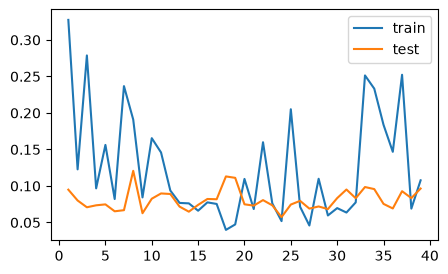

In [107]:
# code here
plt.figure(figsize=(5,3))
plt.plot(range(1, len(train_loss)+1), train_loss, label="train")
plt.plot(range(1, len(train_loss)+1), test_loss, label="test")
plt.legend()
plt.show()

## **6. 모델 평가**

**Q1. 학습된 모델로 test 데이터에 대한 예측값을 구하세요.**

- 다중 분류에서 예측 클래스는 logit이 가장 큰 인덱스입니다.

In [108]:
model.eval()
with torch.no_grad():
    y_pred = model(X_test_tensor)
    softmax = nn.Softmax(dim=1)
    y_pred = softmax(y_pred)

In [109]:
ans = [i.argmax() for i in y_pred]
print(ans)

[tensor(2), tensor(1), tensor(2), tensor(2), tensor(2), tensor(0), tensor(0), tensor(1), tensor(0), tensor(0), tensor(0), tensor(1), tensor(1), tensor(2), tensor(0), tensor(1), tensor(2), tensor(0), tensor(0), tensor(1), tensor(2), tensor(1), tensor(1), tensor(0), tensor(1), tensor(1), tensor(2), tensor(1), tensor(0), tensor(2), tensor(0), tensor(2), tensor(1), tensor(0), tensor(0), tensor(2), tensor(2), tensor(0), tensor(1), tensor(0), tensor(0), tensor(1), tensor(1), tensor(1), tensor(0), tensor(0), tensor(2), tensor(1), tensor(2), tensor(1), tensor(1), tensor(0), tensor(2), tensor(2), tensor(1), tensor(1), tensor(0), tensor(2), tensor(0), tensor(1), tensor(1), tensor(0), tensor(2), tensor(0), tensor(0), tensor(0), tensor(1), tensor(2), tensor(1), tensor(2), tensor(2), tensor(0), tensor(0), tensor(1), tensor(1), tensor(2), tensor(0), tensor(1), tensor(0), tensor(1), tensor(0), tensor(0), tensor(0), tensor(2), tensor(2), tensor(0), tensor(0), tensor(1), tensor(0), tensor(2), tensor(2)

In [110]:
# code here
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print(f"accuracy : {accuracy_score(y_test_tensor, ans)}")

accuracy : 0.9878787878787879


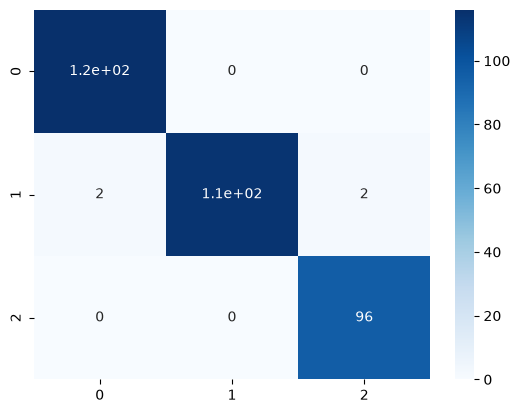

In [111]:
sns.heatmap(confusion_matrix(y_test_tensor, ans), annot=True, cmap="Blues")
plt.show()

In [112]:
print(classification_report(y_test_tensor, ans))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       116
           1       1.00      0.97      0.98       118
           2       0.98      1.00      0.99        96

    accuracy                           0.99       330
   macro avg       0.99      0.99      0.99       330
weighted avg       0.99      0.99      0.99       330



## **7. 채점하기**

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety_submission.csv

In [98]:
submission = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety_submission.csv")
submission.head()

,id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged
0,1,13.801873,0.483173,2.647304,17.792411,106.619039,2.963929,3.126183,0.256605,1.277661,6.954893,1.021307,2.572290,1014.322862,Yes
1,2,13.297159,1.035745,2.203058,21.406817,118.154574,2.454447,2.060823,0.158903,2.252221,6.000669,0.885157,2.036313,1440.503122,No
2,3,14.529306,2.108780,2.302636,21.410780,121.280618,2.856354,2.815771,0.234276,1.527275,6.753056,1.158052,2.855995,1465.288950,Yes
3,4,11.720604,2.227718,2.078144,20.195159,78.944103,1.633732,1.573017,0.566970,1.984541,1.176633,1.314319,2.662910,571.455683,No
4,5,12.731468,0.964084,2.078431,25.308077,66.999211,2.033066,1.629994,0.373080,0.913899,2.549730,1.128514,2.560120,709.025018,Yes


In [99]:
# 동일한 전처리 적용
sub_X = submission.drop(["id"], axis=1).copy()

# 결측치
for col in cols_to_impute:
    sub_X[col] = sub_X[col].fillna(X_train[col].median())
sub_X["oak_aged"] = sub_X["oak_aged"].fillna(mode_val)

# 이상치
for c in numeric_cols:
    sub_X[c] = sub_X[c].clip(d[c][0], d[c][1])

# 인코딩
sub_X["oak_aged"] = le_oak.transform(sub_X["oak_aged"])

# 스케일링 & Tensor 변환
sub_scaled = scaler.transform(sub_X)
sub_t      = torch.tensor(sub_scaled, dtype=torch.float32)

In [ ]:
# code here